# Experimento X1B — De onde vêm os frames não rotulados?

**Pergunta:** a relação temporal entre os frames rotulados e os não rotulados de um batch muda a
efetividade dos métodos semi-supervisionados?

## Por que este experimento existe

Os samplers two-stream da literatura (Mean Teacher, SSL4MIS e descendentes) sorteiam os frames não
rotulados do **pool inteiro**, e isso nunca foi uma decisão: os benchmarks daquela literatura
(ACDC, LA, Pancreas-CT) são coleções de fatias independentes, onde não existe "mesmo vídeo" nem
"frame vizinho". Em vídeo, existe — e vira um grau de liberdade que ninguém controlou.

A intuição a testar: um frame não rotulado 3 frames depois de um rotulado é quase a mesma imagem,
então o termo de consistência aprende pouco mas aprende algo *confiável*; um frame de outro vídeo é
informativo mas o pseudo-rótulo é muito mais arriscado. Existe um ponto ótimo de proximidade, ou a
proximidade não importa?

## As políticas comparadas

| Política | Candidatos para cada slot não rotulado |
|---|---|
| `global` | qualquer frame não rotulado de qualquer vídeo de treino — o que a literatura faz |
| `same_video` | qualquer posição do **mesmo vídeo** de um dos frames rotulados do batch — o default do X1 |
| `temporal_window` W=3 / 5 / 10 | mesmo vídeo, a no máximo W frames de distância do frame rotulado |

Cada slot não rotulado é ancorado num frame rotulado **daquele batch** (round-robin sobre os 4
rotulados). Implementação em [src/data/samplers.py](../../src/data/samplers.py).

## O que é mantido fixo

Tudo o mais. X1B **reutiliza os YAMLs do X1** (`configs/experiment/x1/`) em vez de duplicá-los: o
controle é estrutural, não por convenção — não há como um dos dois divergir sem o outro. O que os
overrides mexem é a política, o pool e o orçamento de rótulos.

Em particular, o **fluxo rotulado é idêntico bit a bit entre as políticas**: com a mesma semente, a
mesma permutação dos frames rotulados sai do sampler em todas as células
(`tests/test_sampling_policies.py::test_labeled_stream_is_identical_across_policies`). Só os slots
não rotulados mudam.

## Duas decisões de desenho que precisam de justificativa

**1. O orçamento principal é 100% dos rótulos.** Sob `same_video` e `temporal_window`, os frames não
rotulados só podem vir de vídeos que *têm* frames rotulados no batch — ou seja, de vídeos de
pacientes revelados. Com 25% dos rótulos isso significa 39 vídeos de 10 pacientes, contra 162 vídeos
de 69 pacientes sob `global`: as políticas passariam a diferir em **cobertura**, não só em
proximidade temporal, e o experimento mediria as duas coisas somadas.

Com 100% dos rótulos todo vídeo de treino tem frames rotulados, as três políticas alcançam os
mesmos 165 vídeos e 69 pacientes, e a única coisa que varia é **de onde dentro do vídeo** o frame
não rotulado vem. É a isolação limpa da pergunta. O orçamento de 25% fica como extensão opcional,
para medir justamente a interação com cobertura — mas lido como uma pergunta diferente.

**2. O pool não rotulado do X1B é denso (`stride=1`, sem teto).** Com o pool do X1 (`stride=3`,
teto 8000), a janela de W=3 fica sem candidatos em ~9% dos sorteios e cai no fallback para
`same_video` — a célula "W=3" seria 90% W=3 e 10% same-video. Com o pool denso (~32k frames), todas
as políticas são servidas 100% das vezes. Isso torna o pool do X1B diferente do pool default do X1;
dentro do X1B ele é o mesmo para todas as células, que é o que a comparação exige.

A Parte 1 audita as duas afirmações acima nos dados reais antes de gastar GPU.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.vfss_frame_dataset import VFSSIncaTrain
from src.data.samplers import (
    TwoStreamBatchSampler,
    labeled_unlabeled_indices,
    frame_index_metadata,
)

## Parâmetros

In [3]:
DATASET_PATH = "/data_ssd/caioseda/data/dataset_inca_all_frames/"

# --- herdado do X1, NAO variar aqui ---
SPLIT_SEED = 42
SPLIT_RATIOS = (0.7, 0.10, 0.2)
SPLIT_GROUP_COLUMN = "paciente_id"
LABEL_SEED = 42
LABEL_GROUP_COLUMN = "paciente_id"
BATCH_SIZE = 8
LABELED_BATCH_SIZE = 4
MAX_STEPS = 8000
VAL_EVERY_N_STEPS = 500
CLASS_IDS = {1: "C2", 3: "C4"}
NUM_CLASSES = 4
METRICS = ["dice", "iou", "assd", "hd95"]

# --- a variavel do X1B ---
# (nome exibido, unlabeled_policy, temporal_window)
POLICIES = [
    ("global",     "global",          None),
    ("same_video", "same_video",      None),   # o default do X1
    ("W=5",        "temporal_window", 5),
    ("W=10",       "temporal_window", 10),
    ("W=15",       "temporal_window", 15),
]

# --- pool DENSO: ver "Duas decisoes de desenho" ---
USE_UNLABELED_POOL = True         # `unlabeled_pool_size=None` e TETO, nao interruptor
UNLABELED_POOL_SIZE = None        # sem teto: todos os frames nunca anotados dos videos de treino
UNLABELED_POOL_FRAME_STRIDE = 1   # sem stride: as janelas temporais precisam de vizinhos
UNLABELED_POOL_SEED = 42
UNLABELED_POOL_SPLITS = ["train"]

# --- grade ---
LABEL_FRACTION = 1.00      # orcamento principal: isola proximidade temporal de cobertura
SEEDS = [42]
# `supervised` roda por politica de proposito: as linhas nao rotuladas passam pelo forward e a UNet
# tem BatchNorm (src/models/modules.py), entao as estatisticas de batch dependem da politica. Uma
# baseline por politica torna o delta "SSL - supervisionado" controlado dentro de cada celula.
METHODS = ["supervised", "fixmatch", "meanteacher", "diffrect"]

REPO_ROOT = Path("../../").resolve()
CONFIG_DIR = REPO_ROOT / "configs/experiment/x1"   # reuso deliberado: ver o cabecalho
LOGS_DIR = REPO_ROOT / "logs"
RESULTS_DIR = LOGS_DIR / "x1b"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = RESULTS_DIR / "results_per_sample.csv"

print(f"Grade: {len(POLICIES)} politicas x {len(METHODS)} metodos x {len(SEEDS)} semente(s) = "
      f"{len(POLICIES) * len(METHODS) * len(SEEDS)} runs de {MAX_STEPS} passos")

Grade: 5 politicas x 3 metodos x 1 semente(s) = 15 runs de 8000 passos


---

# Parte 1 — Auditoria das políticas

Sem GPU: constrói o dataset de treino, roda cada política **a seco** pelo sampler e mede o que ela
de fato entrega. É a parte que decide se a grade de treino vale a pena.

In [4]:
def build_train_dataset(label_fraction, pool_size=UNLABELED_POOL_SIZE,
                        frame_stride=UNLABELED_POOL_FRAME_STRIDE, use_pool=USE_UNLABELED_POOL):
    return VFSSIncaTrain(
        dataset_path=DATASET_PATH, size=256, window_size=1, stride=1, repeat_channels=True,
        mask_interpolation="nearest", target_variant="multiclass_c2_c4",
        split_mode="seed", split_seed=SPLIT_SEED, split_ratios=list(SPLIT_RATIOS),
        split_group_column=SPLIT_GROUP_COLUMN,
        label_group_column=LABEL_GROUP_COLUMN, label_seed=LABEL_SEED,
        label_fraction=label_fraction,
        use_unlabeled_pool=use_pool,
        unlabeled_pool_size=pool_size, unlabeled_pool_frame_stride=frame_stride,
        unlabeled_pool_seed=UNLABELED_POOL_SEED, unlabeled_pool_splits=UNLABELED_POOL_SPLITS,
    )


def make_sampler(dataset, policy, window, seed=42):
    labeled, unlabeled = labeled_unlabeled_indices(dataset)
    return TwoStreamBatchSampler(
        labeled, unlabeled, batch_size=BATCH_SIZE, labeled_batch_size=LABELED_BATCH_SIZE,
        seed=seed, unlabeled_policy=policy, temporal_window=window,
        frame_metadata=frame_index_metadata(dataset),
    )


def audit_policies(dataset, epochs=8, seed=42):
    """Roda cada politica a seco e mede o que ela entrega (sem carregar imagem nenhuma)."""
    df = dataset.video_frame_df
    rows = []
    for name, policy, window in POLICIES:
        sampler = make_sampler(dataset, policy, window, seed=seed)
        drawn = []
        for _ in range(epochs):
            for batch in sampler:
                drawn.extend(batch[LABELED_BATCH_SIZE:])
        report = sampler.draw_report()
        reached = df.iloc[drawn]
        rows.append({
            "politica": name,
            "servida como pedida %": round(100 * report["served_as_requested"], 1),
            "fallback same_video %": round(100 * report["same_video"], 1) if policy == "temporal_window" else np.nan,
            "fallback global %": round(100 * report["global"], 1) if policy != "global" else np.nan,
            "videos alcancados": reached.video_id.nunique(),
            "pacientes alcancados": reached.paciente_id.nunique(),
            "frames distintos": len(set(drawn)),
        })
    return pd.DataFrame(rows).set_index("politica")

### Afirmação 1 — com o pool do X1, a janela W=3 não é servida

Se a coluna "servida como pedida %" ficar abaixo de 100, aquela célula não é o que o rótulo diz que
é: parte dos sorteios caiu no fallback e a célula vira uma mistura de políticas.

In [5]:
dataset_pool_x1 = build_train_dataset(LABEL_FRACTION, pool_size=8000, frame_stride=3)
print(f"Pool do X1: {int((~dataset_pool_x1.video_frame_df.is_labeled).sum())} linhas nao rotuladas")
audit_policies(dataset_pool_x1)

Pool do X1: 8000 linhas nao rotuladas


,servida como pedida %,fallback same_video %,fallback global %,videos alcancados,pacientes alcancados,frames distintos
politica,,,,,,
global,100.0,NaN,NaN,165,69,3967
same_video,100.0,NaN,0.0,165,69,3857
W=5,98.4,1.6,0.0,165,69,1362
W=10,100.0,0.0,0.0,165,69,2117
W=15,100.0,0.0,0.0,165,69,2600


### Afirmação 1 (continuação) — com o pool denso, todas as políticas são servidas

In [6]:
dataset = build_train_dataset(LABEL_FRACTION)
n_unlabeled = int((~dataset.video_frame_df.is_labeled).sum())
STEPS_PER_EPOCH = max(1, int(dataset.video_frame_df.is_labeled.sum()) // LABELED_BATCH_SIZE)
print(f"Pool denso: {n_unlabeled} linhas nao rotuladas "
      f"(stride={UNLABELED_POOL_FRAME_STRIDE}, teto={UNLABELED_POOL_SIZE})")
print(f"Passos por epoca: {STEPS_PER_EPOCH}  =>  {MAX_STEPS // STEPS_PER_EPOCH} epocas ate MAX_STEPS")

audit_denso = audit_policies(dataset)
assert (audit_denso["servida como pedida %"] == 100.0).all(), (
    "Alguma politica caiu em fallback: as celulas do X1B nao seriam o que dizem ser. "
    "Aumente a densidade do pool antes de treinar."
)
audit_denso

Pool denso: 31953 linhas nao rotuladas (stride=1, teto=None)
Passos por epoca: 172  =>  46 epocas ate MAX_STEPS


,servida como pedida %,fallback same_video %,fallback global %,videos alcancados,pacientes alcancados,frames distintos
politica,,,,,,
global,100.0,NaN,NaN,163,69,5059
same_video,100.0,NaN,0.0,165,69,4989
W=5,100.0,0.0,0.0,165,69,3386
W=10,100.0,0.0,0.0,165,69,4054
W=15,100.0,0.0,0.0,165,69,4367


### Afirmação 2 — em 100% dos rótulos, as políticas têm a mesma cobertura

O que valida o orçamento principal. Se `videos alcancados` e `pacientes alcancados` forem iguais
entre as políticas, então a diferença entre elas é só proximidade temporal.

In [7]:
cobertura = audit_denso[["videos alcancados", "pacientes alcancados"]]
assert cobertura["pacientes alcancados"].nunique() == 1, (
    "As politicas alcancam conjuntos de pacientes diferentes: a comparacao mede cobertura + "
    "proximidade temporal, nao so proximidade temporal."
)
print("OK - todas as politicas alcancam os mesmos pacientes neste orcamento.")
display(cobertura)

# E o contraste: no orcamento baixo elas NAO tem a mesma cobertura.
print(f"{chr(10)}O mesmo teste com 25% dos rotulos (por que 100% e o orcamento principal):")
display(audit_policies(build_train_dataset(0.25))[["videos alcancados", "pacientes alcancados"]])

OK - todas as politicas alcancam os mesmos pacientes neste orcamento.


,videos alcancados,pacientes alcancados
politica,,
global,163,69
same_video,165,69
W=5,165,69
W=10,165,69
W=15,165,69



O mesmo teste com 25% dos rotulos (por que 100% e o orcamento principal):


,videos alcancados,pacientes alcancados
politica,,
global,163,69
same_video,39,10
W=5,39,10
W=10,39,10
W=15,39,10


### A distribuição de distâncias temporais

O que cada política de fato produz, em frames de distância entre o rotulado e o não rotulado que o
acompanha. `global` produz distância indefinida (vídeos diferentes) — aparece só a fração de pares
que caem no mesmo vídeo por acaso.

,pares em outro video %,distancia mediana,distancia p90,distancia max
politica,,,,
global,99.4,56,133,148
same_video,0.0,53,140,253
W=5,0.0,3,5,5
W=10,0.0,5,9,10
W=15,0.0,8,14,15


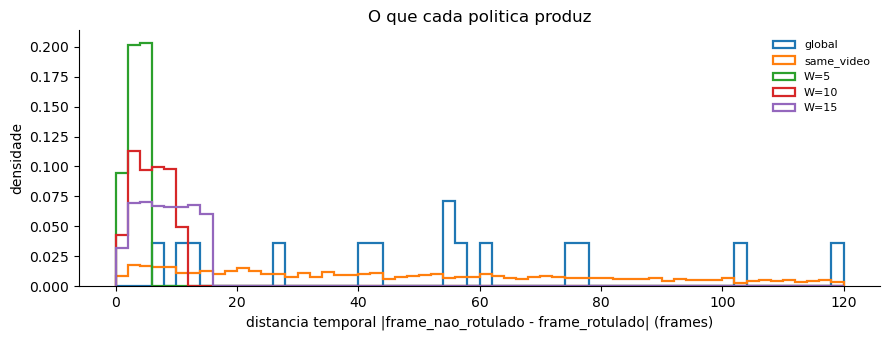

In [9]:
meta = frame_index_metadata(dataset)
videos, frames = meta["video_id"], meta["frame_id"]

distancias = {}
for name, policy, window in POLICIES:
    sampler = make_sampler(dataset, policy, window)
    deltas, outros_videos = [], 0
    for _ in range(4):
        for batch in sampler:
            rotulados, nao_rotulados = batch[:LABELED_BATCH_SIZE], batch[LABELED_BATCH_SIZE:]
            for slot, idx in enumerate(nao_rotulados):
                ancora = rotulados[slot % len(rotulados)]
                if videos[idx] != videos[ancora]:
                    outros_videos += 1
                else:
                    deltas.append(abs(int(frames[idx]) - int(frames[ancora])))
    distancias[name] = {"deltas": np.array(deltas), "outro_video_%": 100 * outros_videos / (len(deltas) + outros_videos)}

resumo = pd.DataFrame([
    {"politica": name,
     "pares em outro video %": round(d["outro_video_%"], 1),
     "distancia mediana": int(np.median(d["deltas"])) if len(d["deltas"]) else np.nan,
     "distancia p90": int(np.percentile(d["deltas"], 90)) if len(d["deltas"]) else np.nan,
     "distancia max": int(d["deltas"].max()) if len(d["deltas"]) else np.nan}
    for name, d in distancias.items()
]).set_index("politica")
display(resumo)

fig, ax = plt.subplots(figsize=(9, 3.5))
for name, d in distancias.items():
    if len(d["deltas"]) == 0:
        continue
    ax.hist(d["deltas"], bins=60, range=(0, 120), histtype="step", label=name, density=True, linewidth=1.6)
ax.set_xlabel("distancia temporal |frame_nao_rotulado - frame_rotulado| (frames)")
ax.set_ylabel("densidade")
ax.set_title("O que cada politica produz")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

---

# Parte 2 — Treino e avaliação

A grade é `semente × política × método`, com `label_fraction` fixo. Os overrides abaixo são a
única coisa que separa uma célula da outra.

In [10]:
import torch
from omegaconf import OmegaConf

from src.experiment import Experiment
from src.evaluation import evaluate_per_class, aggregate_per_class

METHOD_CONFIG = {method: CONFIG_DIR / f"x1-unet-{method}.yaml" for method in
                 ["supervised", "fixmatch", "meanteacher", "diffrect"]}


def run_id(policy_name: str, method: str, seed: int) -> str:
    return f"{method}-{policy_name.replace('=', '')}-s{seed}"


def build_overrides(policy_name, policy, window, method, seed) -> dict:
    """Overrides sobre o YAML do X1. Tudo que nao aparece aqui e identico ao X1 por construcao."""
    return {
        "name": f"x1b-{run_id(policy_name, method, seed)}",
        "trainer": {"params": {
            "max_steps": MAX_STEPS,
            "check_val_every_n_epoch": max(1, round(VAL_EVERY_N_STEPS / STEPS_PER_EPOCH)),
        }},
        "lr_scheduler": {"params": {"T_max": MAX_STEPS}},
        "data": {"params": {
            "batch_size": BATCH_SIZE,
            "shared_dataset_params": {
                "label_fraction": LABEL_FRACTION,
                "label_seed": LABEL_SEED,
                "label_group_column": LABEL_GROUP_COLUMN,
                "split_seed": SPLIT_SEED,
                "split_group_column": SPLIT_GROUP_COLUMN,
                # Pool denso, identico em todas as celulas do X1B.
                "use_unlabeled_pool": USE_UNLABELED_POOL,
                "unlabeled_pool_size": UNLABELED_POOL_SIZE,
                "unlabeled_pool_frame_stride": UNLABELED_POOL_FRAME_STRIDE,
                "unlabeled_pool_seed": UNLABELED_POOL_SEED,
                "unlabeled_pool_splits": UNLABELED_POOL_SPLITS,
                "expose_hidden_targets": True,
            },
            "train_batch_sampler": {"params": {
                "batch_size": BATCH_SIZE,
                "labeled_batch_size": LABELED_BATCH_SIZE,
                "seed": seed,
                # ---- A VARIAVEL DO EXPERIMENTO ----
                "unlabeled_policy": policy,
                "temporal_window": window,
            }},
        }},
    }

/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [11]:
def load_results() -> pd.DataFrame:
    if RESULTS_CSV.exists():
        return pd.read_csv(RESULTS_CSV)
    return pd.DataFrame()


def save_results(results: pd.DataFrame) -> None:
    results.to_csv(RESULTS_CSV, index=False)


def train_and_evaluate(policy_name, policy, window, method, seed):
    experiment = Experiment(
        config_path=str(METHOD_CONFIG[method]),
        overrides=build_overrides(policy_name, policy, window, method, seed),
        log_dir=LOGS_DIR,
    )
    experiment.run(seed=seed)

    forward_fn = getattr(experiment.lit_module, "_eval_forward", None)
    per_sample = evaluate_per_class(
        experiment.lit_module,
        experiment.data_module.test_dataloader(),
        num_classes=NUM_CLASSES,
        class_ids=CLASS_IDS,
        forward_fn=forward_fn,
    )
    per_sample["output_dir"] = str(experiment.experiment_run_dir)

    # Proveniencia: quanto da politica foi de fato servida DURANTE o treino, e nao numa simulacao.
    # Uma celula com `served < 1` e uma mistura de politicas e tem que ser lida assim.
    sampler = experiment.data_module._train_batch_sampler
    report = sampler.draw_report() if sampler is not None else {}
    per_sample["policy_served"] = report.get("served_as_requested", np.nan)
    per_sample["policy_fallback_global"] = report.get("global", np.nan) if policy != "global" else 0.0
    return per_sample

In [ ]:
results = load_results()

for seed in SEEDS:
    for policy_name, policy, window in POLICIES:
        for method in METHODS:
            rid = run_id(policy_name, method, seed)

            if len(results) and (results.run_id == rid).any():
                print(f"[pula] {rid} (ja em {RESULTS_CSV.name})")
                continue

            print(f"[treina] {rid}")
            per_sample = train_and_evaluate(policy_name, policy, window, method, seed)

            per_sample.insert(0, "run_id", rid)
            per_sample.insert(1, "method", method)
            per_sample.insert(2, "policy", policy_name)
            per_sample["temporal_window"] = window if window is not None else np.nan
            per_sample["label_fraction"] = LABEL_FRACTION
            per_sample["seed"] = seed

            results = pd.concat([results, per_sample], ignore_index=True)
            save_results(results)

print(f"{chr(10)}Concluido: {results.run_id.nunique()} runs, {len(results)} linhas em {RESULTS_CSV}")

Seed set to 42


[treina] supervised-global-s42
Loaded configuration: /data_ssd/caioseda/projetos/vfss-seg-benchmark/configs/experiment/x1/x1-unet-supervised.yaml
Console logs: /data_ssd/caioseda/projetos/vfss-seg-benchmark/logs/x1b-supervised-global-s42/2026-09-10-11-17-07/console.log
Seed: 42


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA RTX 6000 Ada Generation') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Using device: cuda:0


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ UNet     │ 17.3 M │ train │     0 │
│ 1 │ dice_loss │ DiceLoss │      0 │ train │     0 │
└───┴───────────┴──────────┴────────┴───────┴───────┘

...

/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

`Trainer.fit` stopped: `max_steps=8000` reached.


Testing best checkpoint: /data_ssd/caioseda/projetos/vfss-seg-benchmark/logs/x1b-fixmatch-W10-s42/2026-09-10-13-49-22/checkpoints/best-epoch=23-step=4127.ckpt


Restoring states from the checkpoint path at /data_ssd/caioseda/projetos/vfss-seg-benchmark/logs/x1b-fixmatch-W10-s42/2026-09-10-13-49-22/checkpoints/best-epoch=23-step=4127.ckpt
/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use 

/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

---

# Parte 3 — Leitura

A pergunta é se a linha de cada método é **plana** ao longo do eixo de proximidade. Plana ⇒ a
relação temporal entre rotulado e não rotulado não importa, e o sampler global da literatura está
bom para vídeo. Não plana ⇒ existe estrutura temporal a explorar, e o X1B localiza onde.

In [ ]:
results = load_results()

# Checagem de proveniencia antes de qualquer leitura.
servido = results.groupby("policy")["policy_served"].min()
if (servido < 1.0).any():
    print("ATENCAO - celulas que NAO rodaram a politica pedida o tempo todo:")
    display(servido[servido < 1.0])
else:
    print("OK - todas as celulas rodaram a politica pedida em 100% dos sorteios.")

aggregated = aggregate_per_class(results, group_columns=["method", "policy", "seed"])
across_seeds = (
    aggregated.groupby(["method", "policy", "class"], as_index=False)[METRICS].mean()
)

POLICY_ORDER = [name for name, _, _ in POLICIES]
table = across_seeds.pivot_table(index=["method", "policy"], columns="class", values=METRICS)
table = table.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0)
table.reindex(pd.MultiIndex.from_product([METHODS, POLICY_ORDER], names=["method", "policy"])).round(4)

In [ ]:
fig, axes = plt.subplots(len(METRICS), len(CLASS_IDS),
                         figsize=(10, 3.0 * len(METRICS)), squeeze=False)
class_names = list(CLASS_IDS.values())
colors = {"supervised": "#333333", "fixmatch": "#4C72B0", "meanteacher": "#DD8452"}
x = np.arange(len(POLICY_ORDER))

for row, metric in enumerate(METRICS):
    for col, class_name in enumerate(class_names):
        ax = axes[row][col]
        subset = across_seeds[across_seeds["class"] == class_name]
        for method in METHODS:
            data = (subset[subset.method == method]
                    .set_index("policy").reindex(POLICY_ORDER)[metric])
            style = "o--" if method == "supervised" else "o-"
            ax.plot(x, data.values, style, label=method, color=colors.get(method),
                    linewidth=2 if method == "supervised" else 1.6)
        ax.set_xticks(x); ax.set_xticklabels(POLICY_ORDER, rotation=20)
        ax.set_xlabel("politica de amostragem (esq.: solto  ->  dir.: proximo)")
        ax.set_ylabel(metric)
        ax.set_title(f"{metric.upper()} - {class_name}" + ("  (menor e melhor)" if metric in ("assd", "hd95") else ""))
        ax.spines[["top", "right"]].set_visible(False)
        if row == 0 and col == 0:
            ax.legend(frameon=False, fontsize=8)

plt.tight_layout()

### O efeito da política, isolado

Para cada método, o ganho sobre o supervisionado **da mesma política** — o que remove qualquer
efeito de segunda ordem que a política tenha sobre a baseline (as linhas não rotuladas passam pelo
forward e a UNet tem BatchNorm).

In [ ]:
efeito = []
for class_name in class_names:
    for policy_name in POLICY_ORDER:
        base = across_seeds[(across_seeds.method == "supervised") &
                            (across_seeds.policy == policy_name) &
                            (across_seeds["class"] == class_name)]["dice"]
        if base.empty:
            continue
        for method in [m for m in METHODS if m != "supervised"]:
            data = across_seeds[(across_seeds.method == method) &
                                (across_seeds.policy == policy_name) &
                                (across_seeds["class"] == class_name)]["dice"]
            if data.empty:
                continue
            efeito.append({"classe": class_name, "politica": policy_name, "metodo": method,
                           "dice": round(data.iloc[0], 4),
                           "supervisionado (mesma politica)": round(base.iloc[0], 4),
                           "ganho SSL": round(data.iloc[0] - base.iloc[0], 4)})

efeito_df = pd.DataFrame(efeito)
if len(efeito_df):
    display(efeito_df.pivot_table(index=["classe", "metodo"], columns="politica",
                                  values="ganho SSL").reindex(columns=POLICY_ORDER).round(4))
    print("Leitura: linha plana => a proximidade temporal nao muda o valor do termo nao supervisionado.")
    print("         crescente da esquerda para a direita => quanto mais proximo, melhor.")
    print("         com pico no meio => existe uma distancia otima, e ela e o achado do X1B.")
else:
    efeito_df

---

## Notas

**Uma semente não decide nada.** Com `SEEDS = [42]` as diferenças entre políticas não têm barra de
erro, e a escala do efeito esperado aqui é pequena. Antes de concluir qualquer coisa sobre a forma
da curva, rode ao menos 3 sementes — é a extensão de maior retorno deste notebook.

**Diagnóstico por política.** `train/pseudo_accuracy` e `train/teacher_dice` (medidos contra a GT
que o regime escondeu) devem responder à política de forma previsível: quanto mais próximo o frame
não rotulado, mais fácil o pseudo-rótulo e maior a acurácia — com menos informação nova. Se a
acurácia do pseudo-rótulo subir com a proximidade mas o Dice de teste não, o gargalo não é a
qualidade do alvo. Em `label_fraction=1.0` não há rótulo escondido e essas curvas ficam vazias;
é o preço do orçamento principal, e mais uma razão para rodar a extensão em 25%.

**Extensão em orçamento baixo.** Trocar `LABEL_FRACTION` para 0.25 responde uma pergunta *diferente*
— política + cobertura juntas — e a Parte 1 já mostra o quanto a cobertura varia ali. Vale rodar,
desde que lido como outra pergunta e não como réplica desta.

**Relação com o X1.** O X1 usa `same_video` como default. Se o X1B mostrar que `global` é
consistentemente melhor, o default do X1 precisa ser revisto — e as conclusões do X1 relidas à luz
disso.